## Configuration, map

In [7]:
import json
import time
from collections import deque
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import math

SEED = 42
GAMMA = 0.95
THETA = 1e-8
MAX_STEPS = 150

EVAL_EPISODES = 1
Q_EPISODES = 12000
SARSA_EPISODES = 12000
MC_EPISODES = 12000
TD_EPISODES = 12000
ALPHA = 0.10
EPSILON_START = 1.0
EPSILON_END = 0.05
EPSILON_DECAY = 0.9995

REWARDS = {
    "step": -1,
    "key": 5,
    "goal": 20,
    "invalid": -2,
    "recreated_key": 5
}
ACTIONS = [(-1, 0), (1, 0), (0, -1), (0, 1)]
ACTION_NAMES = ["Up", "Down", "Left", "Right"]
ACTION_ARROWS = {"Up": "↑", "Down": "↓", "Left": "←", "Right": "→"}

MAPS = {
    "Map 1 - Basic": [
        "S..W..G",
        ".W.W.W.",
        ".K.DR..",
        ".W.W.W.",
        "...W..."
    ],
    "Map 2 - Intermediate": [
        "S...W..G",
        ".W..W.W.",
        "..K.W...",
        "....DR..",
        ".W..W.W.",
        "....W...",
        ".W......",
        "....W..."
    ],
    "Map 3 - Advanced": [
        "S....W...G",
        ".W...W.W..",
        "..K..W....",
        "...W.W....",
        ".W...W.W..",
        ".....DR...",
        ".W...W.W..",
        "...W.W....",
        ".W...W....",
        ".....W...."
    ]
}

RESULTS_DIR = Path("Key_Door_Grid_World") / "results"
FIGURES_DIR = Path("Key_Door_Grid_World") / "figures"
MAPS_DIR = Path("Key_Door_Grid_World") / "maps"
for folder in (RESULTS_DIR, FIGURES_DIR, MAPS_DIR):
    folder.mkdir(parents=True, exist_ok=True)

np.random.seed(SEED)

def validate_map(grid):
    if not grid or not grid[0] or any(len(row) != len(grid[0]) for row in grid):
        raise ValueError("All map rows must have the same non-zero width.")
    cells = "".join(grid)
    for symbol in ("S", "K", "D", "R", "G"):
        if cells.count(symbol) != 1:
            raise ValueError(f"Bản đồ phải chứa chính xác 1 {symbol}")
    allowed = set("S G K D R W .".split())
    if any(char not in allowed for char in cells):
        raise ValueError("Bản đồ chứa ký hiệu không được hỗ trợ")
    return len(grid), len(grid[0])

for name, grid in MAPS.items():
    validate_map(grid)

map_legend = {
    "S": "Start",
    "G": "Goal",
    "K": "Original key",
    "D": "Locked door",
    "R": "One-time key recreation",
    "W": "Wall",
    ".": "Empty cell"
}

##KeyDoorEnv


In [8]:
class KeyDoorEnv:
    def __init__(self, grid, rewards=None):
        self.grid = list(grid)
        self.rows, self.cols = validate_map(self.grid)
        self.rewards = dict(REWARDS if rewards is None else rewards)
        self.start = self._find("S")
        self.goal = self._find("G")
        self.key_pos = self._find("K")
        self.door_pos = self._find("D")
        self.recreation_pos = self._find("R")
        self.initial_state = (*self.start, False, False, True)

    def _find(self, symbol):
        for r, row in enumerate(self.grid):
            for c, value in enumerate(row):
                if value == symbol:
                    return r, c
        raise ValueError(f"Thiếu biểu tượng trên bản đồ: {symbol}")

    def is_terminal(self, state):
        return state[:2] == self.goal

    def transition(self, state, action):
        if self.is_terminal(state):
            return state, 0.0, "terminal"
        r, c, has_key, door_open, recreation_available = state
        dr, dc = ACTIONS[int(action)]
        nr, nc = r + dr, c + dc

        if not (0 <= nr < self.rows and 0 <= nc < self.cols):
            return state, self.rewards["invalid"], "invalid"
        tile = self.grid[nr][nc]
        if tile == "W":
            return state, self.rewards["invalid"], "invalid"

        next_has_key = has_key
        next_door_open = door_open
        next_recreation_available = recreation_available
        reward = self.rewards["step"]
        event = "move"

        if tile == "D" and not next_door_open:
            if not next_has_key:
                return state, self.rewards["invalid"], "locked_door"
            next_has_key = False
            next_door_open = True
            event = "door_opened"

        if tile == "K" and not next_has_key and not next_door_open:
            next_has_key = True
            reward += self.rewards["key"]
            event = "original_key_collected"

        if tile == "R" and next_door_open and next_recreation_available and not next_has_key:
            next_has_key = True
            next_recreation_available = False
            reward += self.rewards["recreated_key"]
            event = "key_recreated"

        if tile == "G":
            reward += self.rewards["goal"]
            event = "goal"

        next_state = (nr, nc, next_has_key, next_door_open, next_recreation_available)
        return next_state, reward, event

    def reachable_states(self):
        visited = {self.initial_state}
        queue = deque([self.initial_state])
        while queue:
            state = queue.popleft()
            if self.is_terminal(state):
                continue
            for action in range(len(ACTIONS)):
                next_state, _, _ = self.transition(state, action)
                if next_state not in visited:
                    visited.add(next_state)
                    queue.append(next_state)
        return sorted(visited)

def build_model(env, states):
    state_set = set(states)
    model = {}
    for state in states:
        model[state] = []
        for action in range(len(ACTIONS)):
            next_state, reward, event = env.transition(state, action)
            if next_state not in state_set:
                raise RuntimeError("The model reached a state absent from reachable_states().")
            model[state].append((next_state, reward, event))
    return model

def render_map(grid, ax=None, title=None):
    if ax is None:
        _, ax = plt.subplots(figsize=(max(5, len(grid[0]) * 0.65), max(3, len(grid) * 0.55)))
    ax.imshow(np.zeros((len(grid), len(grid[0]))), cmap="Greys", vmin=0, vmax=3)
    colors = {"S": "#b7e4c7", "G": "#90caf9", "K": "#ffe082", "D": "#ef9a9a", "R": "#ce93d8", "W": "#616161", ".": "#ffffff"}
    for r, row in enumerate(grid):
        for c, tile in enumerate(row):
            ax.add_patch(plt.Rectangle((c - .5, r - .5), 1, 1, facecolor=colors[tile], edgecolor="#999999"))
            ax.text(c, r, tile, ha="center", va="center", fontsize=12, color="black" if tile != "W" else "white", fontweight="bold")
    ax.set_xticks(range(len(grid[0])))
    ax.set_yticks(range(len(grid)))
    ax.set_xticklabels([])
    ax.set_yticklabels([])
    ax.grid(False)
    ax.set_title(title or "Key-Door Grid World")
    ax.set_xlim(-0.5, len(grid[0]) - 0.5)
    ax.set_ylim(len(grid) - 0.5, -0.5)
    return ax

## Environmental testing

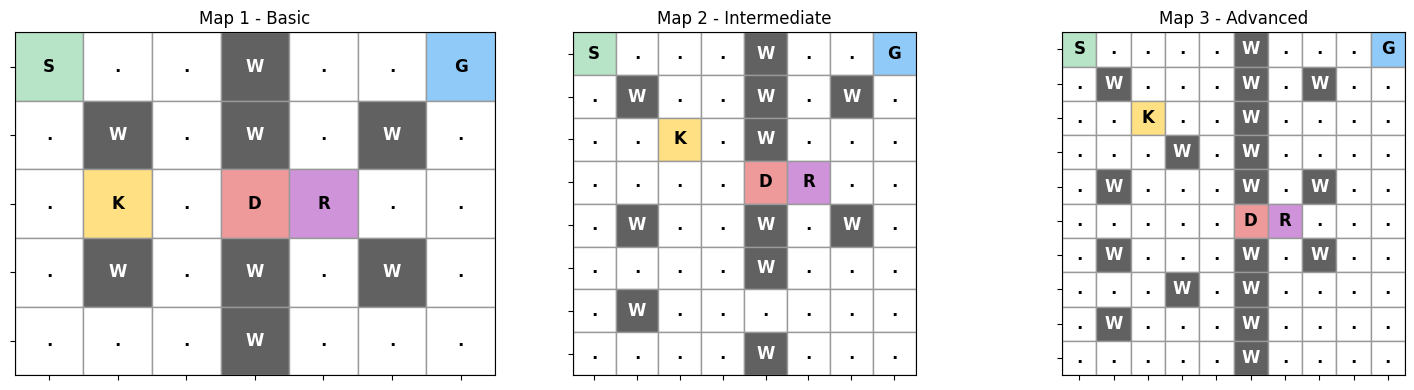

,map,height,width,reachable_states,goal_reachable,actions
0,Map 1 - Basic,5,7,66,True,4
1,Map 2 - Intermediate,8,8,208,True,4
2,Map 3 - Advanced,10,10,214,True,4


In [9]:
map_overview = []
for map_name, grid in MAPS.items():
    env = KeyDoorEnv(grid)
    states = env.reachable_states()
    model = build_model(env, states)
    map_overview.append({
        "map": map_name,
        "height": env.rows,
        "width": env.cols,
        "reachable_states": len(states),
        "goal_reachable": any(env.is_terminal(state) for state in states),
        "actions": len(ACTIONS)
    })

fig, axes = plt.subplots(1, len(MAPS), figsize=(5 * len(MAPS), 4))
for ax, (name, grid) in zip(np.atleast_1d(axes), MAPS.items()):
    render_map(grid, ax=ax, title=name)
plt.tight_layout()
plt.show()
display(pd.DataFrame(map_overview))

for map_name, grid in MAPS.items():
    env_check = KeyDoorEnv(grid)
    reachable = env_check.reachable_states()
    assert any(env_check.is_terminal(state) for state in reachable), f"Goal unreachable: {map_name}"
    assert len(reachable) > 0

test_env = KeyDoorEnv(MAPS["Map 1 - Basic"])
assert len(test_env.initial_state) == 5
assert test_env.is_terminal((*test_env.goal, False, True, False))
assert len(test_env.reachable_states()) > 0

key_state, key_reward, key_event = test_env.transition((2, 0, False, False, True), 3)
assert key_state == (2, 1, True, False, True) and key_event == "original_key_collected"

door_state, door_reward, door_event = test_env.transition((2, 2, True, False, True), 3)
assert door_state == (2, 3, False, True, True) and door_event == "door_opened"

recreated_state, recreated_reward, recreated_event = test_env.transition(door_state, 3)
assert recreated_state == (2, 4, True, True, False) and recreated_event == "key_recreated"

no_recollect_state, _, no_recollect_event = test_env.transition((2, 2, False, True, False), 2)
assert no_recollect_state[2] is False and no_recollect_event == "move"

locked_state, locked_reward, locked_event = test_env.transition((2, 2, False, False, True), 3)
assert locked_state == (2, 2, False, False, True) and locked_event == "locked_door"
assert locked_reward == test_env.rewards["invalid"]

boundary_state, boundary_reward, boundary_event = test_env.transition((0, 0, False, False, True), 0)
assert boundary_state == (0, 0, False, False, True) and boundary_event == "invalid"
assert boundary_reward == test_env.rewards["invalid"]

terminal_state = (*test_env.goal, False, True, False)
terminal_next, terminal_reward, terminal_event = test_env.transition(terminal_state, 0)
assert terminal_next == terminal_state and terminal_reward == 0.0 and terminal_event == "terminal"

wall_state, wall_reward, wall_event = test_env.transition((0, 2, False, False, True), 3)
assert wall_state == (0, 2, False, False, True) and wall_event == "invalid"
assert wall_reward == test_env.rewards["invalid"]


## Algorithm

In [10]:
def value_iteration(env, gamma=GAMMA, theta=THETA, max_iterations=10000):
    start = time.perf_counter()
    states = env.reachable_states()
    model = build_model(env, states)
    values = {s: 0.0 for s in states}

    for iteration in range(1, max_iterations + 1):
        delta = 0.0
        updated = values.copy()
        for state in states:
            if env.is_terminal(state):
                updated[state] = 0.0
                continue
            updated[state] = max(reward + gamma * values[next_state]
                                 for next_state, reward, _ in model[state])
            delta = max(delta, abs(updated[state] - values[state]))
        values = updated
        if delta < theta:
            break

    policy = {}
    for state in states:
        if env.is_terminal(state):
            policy[state] = 0
        else:
            action_values = [reward + gamma * values[next_state]
                             for next_state, reward, _ in model[state]]
            policy[state] = int(np.argmax(action_values))
    return policy, {"values": values, "iterations": iteration, "runtime_seconds": time.perf_counter() - start}

def policy_iteration(env, gamma=GAMMA, theta=THETA, max_iterations=1000):
    start = time.perf_counter()
    states = env.reachable_states()
    model = build_model(env, states)
    values = {s: 0.0 for s in states}
    policy = {s: 0 for s in states}

    for iteration in range(1, max_iterations + 1):
        while True:
            delta = 0.0
            updated = values.copy()
            for state in states:
                if env.is_terminal(state):
                    updated[state] = 0.0
                    continue
                next_state, reward, _ = model[state][policy[state]]
                updated[state] = reward + gamma * values[next_state]
                delta = max(delta, abs(updated[state] - values[state]))
            values = updated
            if delta < theta:
                break

        stable = True
        for state in states:
            if env.is_terminal(state):
                continue
            action_values = [reward + gamma * values[next_state]
                             for next_state, reward, _ in model[state]]
            best_action = int(np.argmax(action_values))
            if best_action != policy[state]:
                policy[state] = best_action
                stable = False
        if stable:
            break

    return policy, {"values": values, "iterations": iteration, "runtime_seconds": time.perf_counter() - start}

def epsilon_greedy(Q, state, rng, epsilon):
    if rng.random() < epsilon:
        return int(rng.integers(len(ACTIONS)))
    values = np.asarray(Q[state], dtype=float)
    best = np.flatnonzero(np.isclose(values, values.max()))
    return int(rng.choice(best))

def q_learning(env, episodes=Q_EPISODES, seed=SEED, alpha=ALPHA, gamma=GAMMA):
    start = time.perf_counter()
    rng = np.random.default_rng(seed)
    states = env.reachable_states()
    Q = {s: np.zeros(len(ACTIONS), dtype=float) for s in states}
    returns = []
    epsilon = EPSILON_START

    for _ in range(episodes):
        state = env.initial_state
        total = 0.0
        for _ in range(MAX_STEPS):
            action = epsilon_greedy(Q, state, rng, epsilon)
            next_state, reward, _ = env.transition(state, action)
            target = reward if env.is_terminal(next_state) else reward + gamma * np.max(Q[next_state])
            Q[state][action] += alpha * (target - Q[state][action])
            total += reward
            state = next_state
            if env.is_terminal(state):
                break
        returns.append(float(total))
        epsilon = max(EPSILON_END, epsilon * EPSILON_DECAY)

    policy = {s: int(np.argmax(q)) for s, q in Q.items()}
    return policy, {"Q": Q, "learning_returns": returns, "episodes": episodes, "runtime_seconds": time.perf_counter() - start}

def sarsa(env, episodes=SARSA_EPISODES, seed=SEED, alpha=ALPHA, gamma=GAMMA):
    start = time.perf_counter()
    rng = np.random.default_rng(seed)
    states = env.reachable_states()
    Q = {s: np.zeros(len(ACTIONS), dtype=float) for s in states}
    returns = []
    epsilon = EPSILON_START

    for _ in range(episodes):
        state = env.initial_state
        action = epsilon_greedy(Q, state, rng, epsilon)
        total = 0.0
        for _ in range(MAX_STEPS):
            next_state, reward, _ = env.transition(state, action)
            total += reward
            if env.is_terminal(next_state):
                target = reward
                Q[state][action] += alpha * (target - Q[state][action])
                break
            next_action = epsilon_greedy(Q, next_state, rng, epsilon)
            target = reward + gamma * Q[next_state][next_action]
            Q[state][action] += alpha * (target - Q[state][action])
            state, action = next_state, next_action
        returns.append(float(total))
        epsilon = max(EPSILON_END, epsilon * EPSILON_DECAY)

    policy = {s: int(np.argmax(q)) for s, q in Q.items()}
    return policy, {"Q": Q, "learning_returns": returns, "episodes": episodes, "runtime_seconds": time.perf_counter() - start}

def monte_carlo_control(env, episodes=MC_EPISODES, seed=SEED, gamma=GAMMA):
    start = time.perf_counter()
    rng = np.random.default_rng(seed)
    states = env.reachable_states()
    Q = {s: np.zeros(len(ACTIONS), dtype=float) for s in states}
    returns_sum = {(s, a): 0.0 for s in states for a in range(len(ACTIONS))}
    returns_count = {(s, a): 0 for s in states for a in range(len(ACTIONS))}
    episode_returns = []
    epsilon = EPSILON_START

    for _ in range(episodes):
        state = env.initial_state
        trajectory = []
        total = 0.0
        for _ in range(MAX_STEPS):
            action = epsilon_greedy(Q, state, rng, epsilon)
            next_state, reward, _ = env.transition(state, action)
            trajectory.append((state, action, float(reward)))
            total += reward
            state = next_state
            if env.is_terminal(state):
                break

        G = 0.0
        returns_by_time = [0.0] * len(trajectory)
        for t in range(len(trajectory) - 1, -1, -1):
            G = trajectory[t][2] + gamma * G
            returns_by_time[t] = G

        first_visit = set()
        for (state_t, action_t, _), G_t in zip(trajectory, returns_by_time):
            pair = (state_t, action_t)
            if pair not in first_visit:
                first_visit.add(pair)
                returns_sum[pair] += G_t
                returns_count[pair] += 1
                Q[state_t][action_t] = returns_sum[pair] / returns_count[pair]

        episode_returns.append(float(total))
        epsilon = max(EPSILON_END, epsilon * EPSILON_DECAY)

    policy = {s: int(np.argmax(q)) for s, q in Q.items()}
    return policy, {"Q": Q, "learning_returns": episode_returns, "episodes": episodes, "runtime_seconds": time.perf_counter() - start}

def td_zero_control(env, episodes=TD_EPISODES, seed=SEED, alpha=ALPHA, gamma=GAMMA):
    start = time.perf_counter()
    rng = np.random.default_rng(seed)
    states = env.reachable_states()
    model = build_model(env, states)
    values = {state: 0.0 for state in states}
    returns = []
    epsilon = EPSILON_START

    def action_values(state):
        return np.asarray([
            reward + (0.0 if env.is_terminal(next_state) else gamma * values[next_state])
            for next_state, reward, _ in model[state]
        ], dtype=float)

    for _ in range(episodes):
        state = env.initial_state
        total = 0.0
        for _ in range(MAX_STEPS):
            if rng.random() < epsilon:
                action = int(rng.integers(len(ACTIONS)))
            else:
                candidates = np.flatnonzero(np.isclose(action_values(state), action_values(state).max()))
                action = int(rng.choice(candidates))
            next_state, reward, _ = env.transition(state, action)
            target = reward if env.is_terminal(next_state) else reward + gamma * values[next_state]
            values[state] += alpha * (target - values[state])
            total += reward
            state = next_state
            if env.is_terminal(state):
                break
        returns.append(float(total))
        epsilon = max(EPSILON_END, epsilon * EPSILON_DECAY)

    policy = {}
    for state in states:
        if env.is_terminal(state):
            policy[state] = 0
        else:
            policy[state] = int(np.argmax(action_values(state)))
    return policy, {"values": values, "learning_returns": returns, "episodes": episodes, "runtime_seconds": time.perf_counter() - start}

ALGORITHMS = {
    "Value Iteration": lambda env, seed: value_iteration(env),
    "Policy Iteration": lambda env, seed: policy_iteration(env),
    "Q-learning": lambda env, seed: q_learning(env, seed=seed),
    "SARSA": lambda env, seed: sarsa(env, seed=seed),
    "Monte Carlo": lambda env, seed: monte_carlo_control(env, seed=seed),
    "TD(0) Control": lambda env, seed: td_zero_control(env, seed=seed)
}

## Training and assessment

In [11]:
def run_episode(env, policy, max_steps=MAX_STEPS):
    state = env.initial_state
    total_return = 0.0
    events = []
    path = [state]
    for _ in range(max_steps):
        if env.is_terminal(state):
            break
        action = policy.get(state, 0)
        next_state, reward, event = env.transition(state, action)
        total_return += reward
        events.append(event)
        state = next_state
        path.append(state)
        if env.is_terminal(state):
            break
    return {
        "return": float(total_return),
        "steps": len(path) - 1,
        "success": env.is_terminal(state),
        "events": events,
        "path": path
    }

def evaluate_policy(env, policy, episodes=EVAL_EPISODES):
    runs = [run_episode(env, policy) for _ in range(episodes)]
    representative = runs[0]
    events = representative["events"]
    path = representative["path"]
    door_open_seen = False
    recollected_original_key = False
    for event in events:
        if event == "door_opened":
            door_open_seen = True
        elif event == "original_key_collected" and door_open_seen:
            recollected_original_key = True

    return {
        "success_rate_pct": 100.0 * np.mean([run["success"] for run in runs]),
        "mean_return": float(np.mean([run["return"] for run in runs])),
        "return_std": float(np.std([run["return"] for run in runs])),
        "mean_steps": float(np.mean([run["steps"] for run in runs])),
        "original_key_collected": "original_key_collected" in events,
        "door_opened": "door_opened" in events,
        "key_recreated": "key_recreated" in events,
        "recreation_consumed": any(path[i-1][4] and not path[i][4] for i in range(1, len(path))),
        "goal_reached": representative["success"],
        "original_key_recollected_after_open": recollected_original_key,
        "representative_episode": representative
    }

experiment_rows = []
trained_policies = {}
trained_infos = {}
learning_curves = {}
representative_episodes = {}

for map_index, (map_name, grid) in enumerate(MAPS.items()):
    env = KeyDoorEnv(grid)
    states = env.reachable_states()
    for algorithm_name, train_function in ALGORITHMS.items():
        policy, info = train_function(env, SEED + map_index)
        evaluation = evaluate_policy(env, policy)
        representative = evaluation["representative_episode"]
        checks = (
            evaluation["original_key_collected"]
            and evaluation["door_opened"]
            and evaluation["key_recreated"]
            and evaluation["recreation_consumed"]
            and evaluation["goal_reached"]
            and not evaluation["original_key_recollected_after_open"]
        )
        trained_policies[(map_name, algorithm_name)] = policy
        trained_infos[(map_name, algorithm_name)] = info
        representative_episodes[(map_name, algorithm_name)] = representative
        if "learning_returns" in info:
            learning_curves[(map_name, algorithm_name)] = info["learning_returns"]
        experiment_rows.append({
            "map": map_name,
            "algorithm": algorithm_name,
            "reachable_states": len(states),
            "success_rate_pct": evaluation["success_rate_pct"],
            "mean_return": evaluation["mean_return"],
            "return_std": evaluation["return_std"],
            "mean_steps": evaluation["mean_steps"],
            "runtime_seconds": info["runtime_seconds"],
            "training_episodes": info.get("episodes", 0),
            "original_key_collected": evaluation["original_key_collected"],
            "door_opened": evaluation["door_opened"],
            "key_recreated": evaluation["key_recreated"],
            "recreation_consumed": evaluation["recreation_consumed"],
            "goal_reached": evaluation["goal_reached"],
            "all_mechanics_checks_passed": bool(checks)
        })

results_df = pd.DataFrame(experiment_rows)
display(results_df.round(3))

,map,algorithm,reachable_states,success_rate_pct,mean_return,return_std,mean_steps,runtime_seconds,training_episodes,original_key_collected,door_opened,key_recreated,recreation_consumed,goal_reached,all_mechanics_checks_passed
0,Map 1 - Basic,Value Iteration,66,100.0,20.0,0.0,10.0,0.003,0,True,True,True,True,True,True
1,Map 1 - Basic,Policy Iteration,66,100.0,20.0,0.0,10.0,0.027,0,True,True,True,True,True,True
2,Map 1 - Basic,Q-learning,66,100.0,20.0,0.0,10.0,7.475,12000,True,True,True,True,True,True
3,Map 1 - Basic,SARSA,66,100.0,20.0,0.0,10.0,7.189,12000,True,True,True,True,True,True
4,Map 1 - Basic,Monte Carlo,66,100.0,20.0,0.0,10.0,7.688,12000,True,True,True,True,True,True
5,Map 1 - Basic,TD(0) Control,66,100.0,20.0,0.0,10.0,6.899,12000,True,True,True,True,True,True
6,Map 2 - Intermediate,Value Iteration,208,100.0,17.0,0.0,13.0,0.006,0,True,True,True,True,True,True
7,Map 2 - Intermediate,Policy Iteration,208,100.0,17.0,0.0,13.0,0.086,0,True,True,True,True,True,True
8,Map 2 - Intermediate,Q-learning,208,100.0,17.0,0.0,13.0,9.937,12000,True,True,True,True,True,True
9,Map 2 - Intermediate,SARSA,208,100.0,17.0,0.0,13.0,9.153,12000,True,True,True,True,True,True


##Compare results and visualize


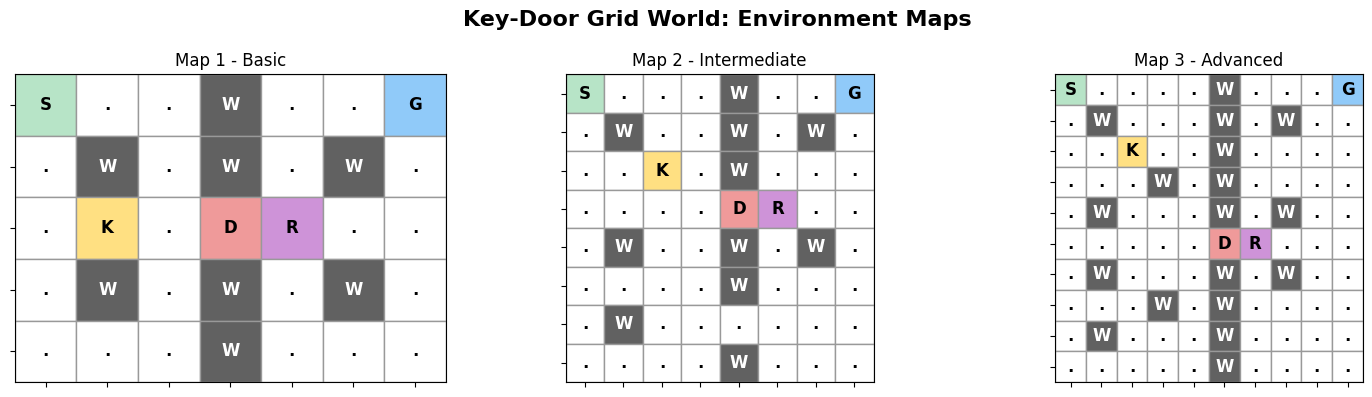

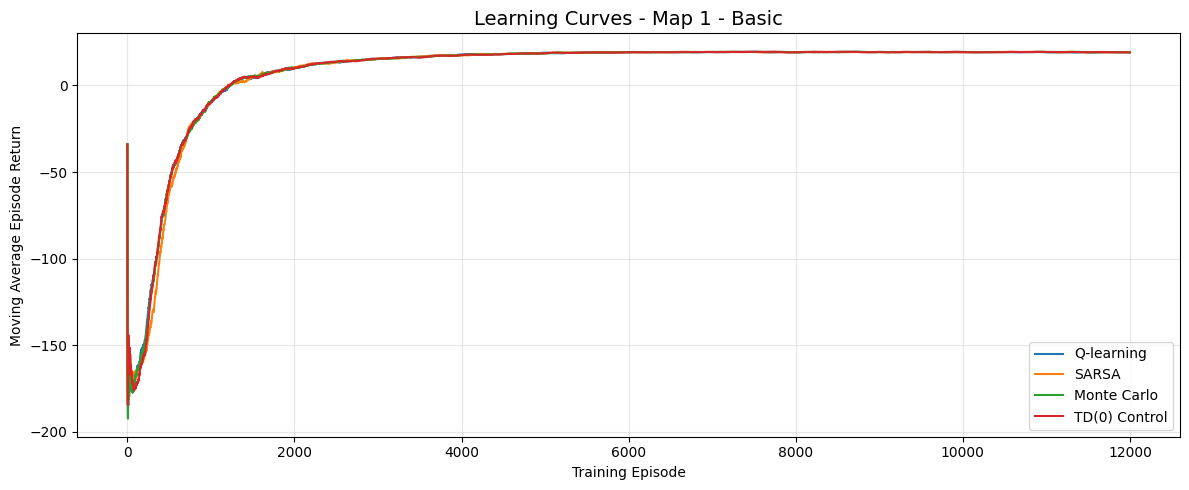

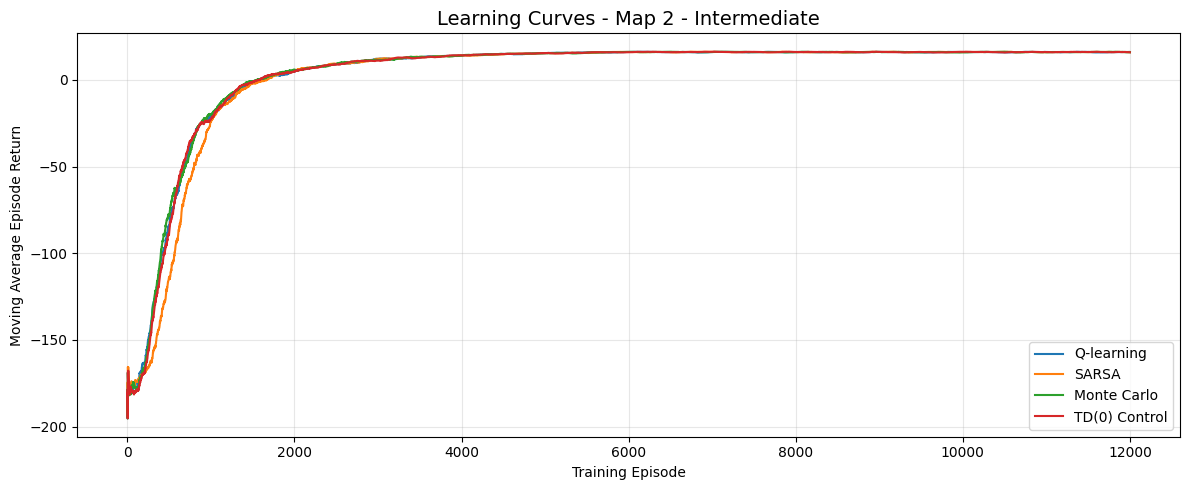

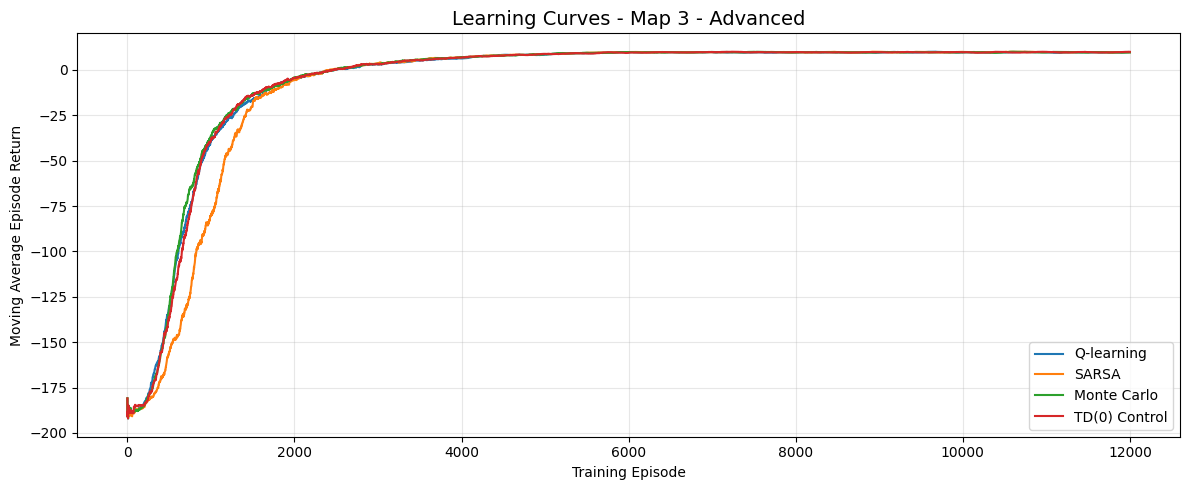

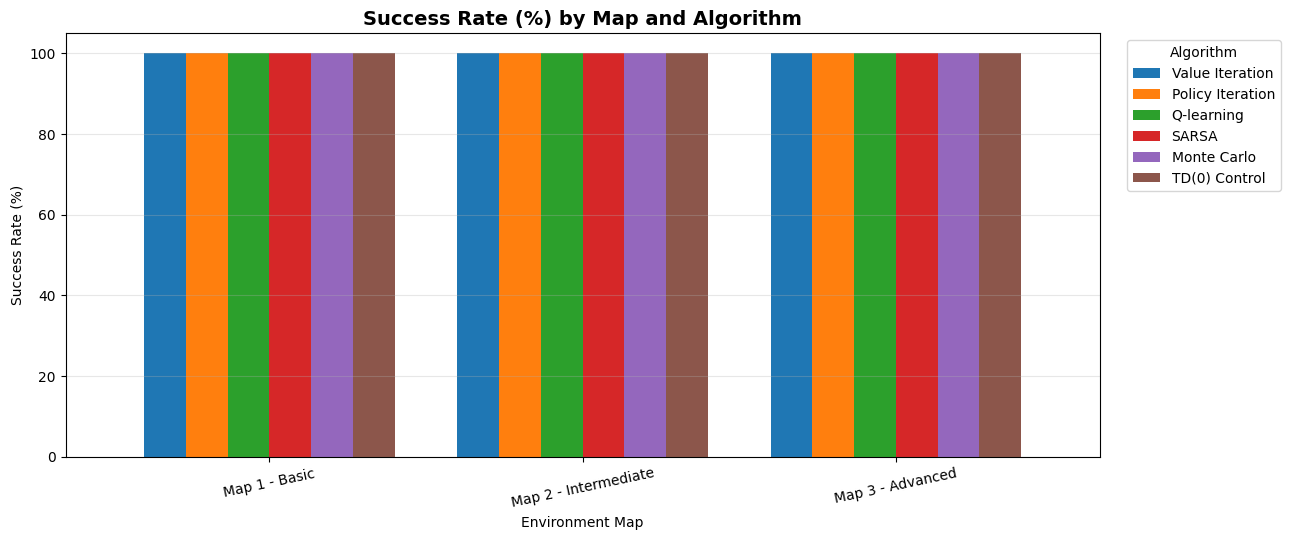

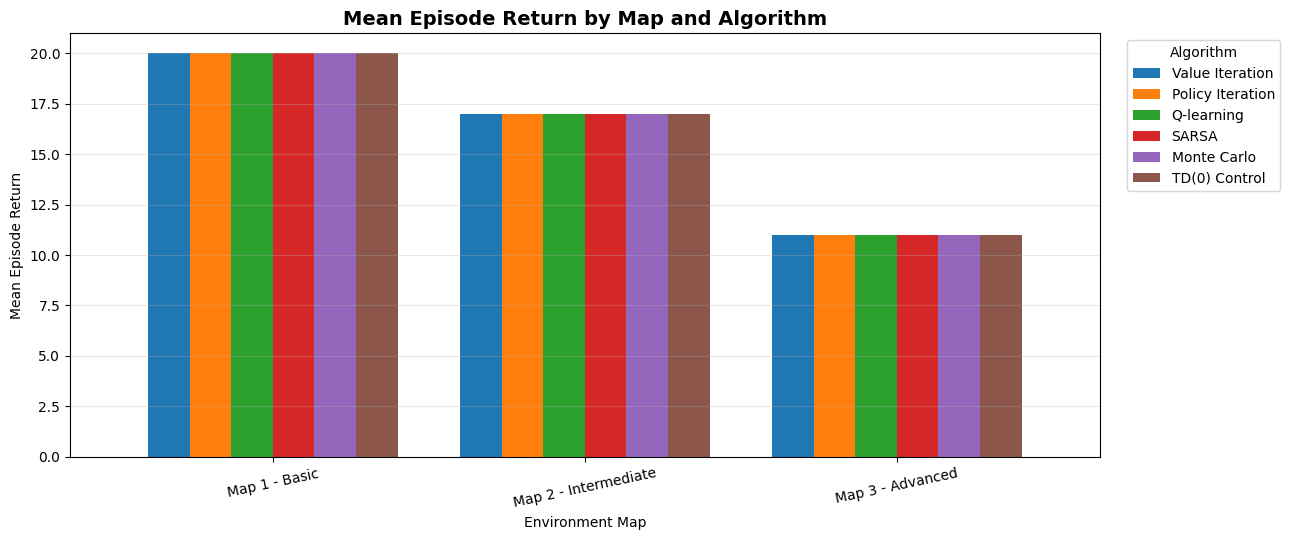

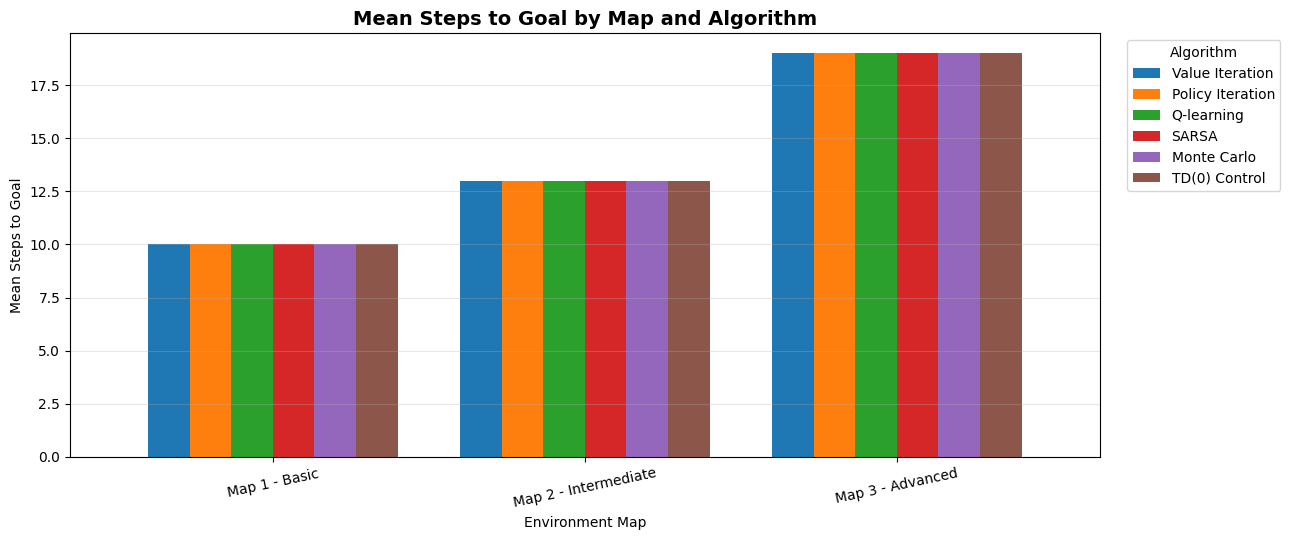

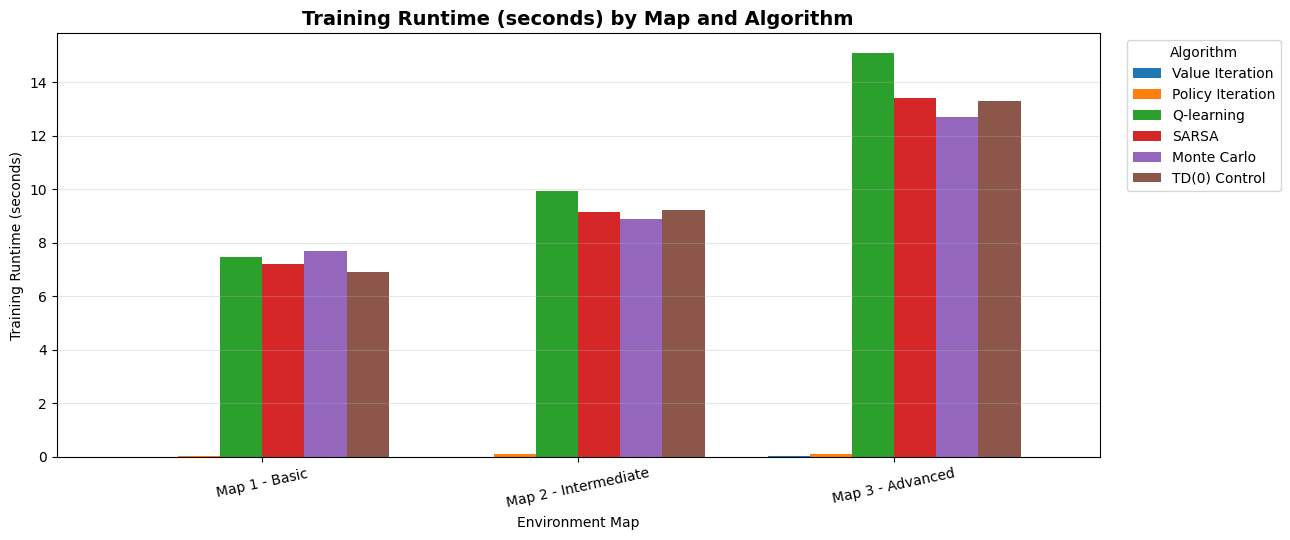

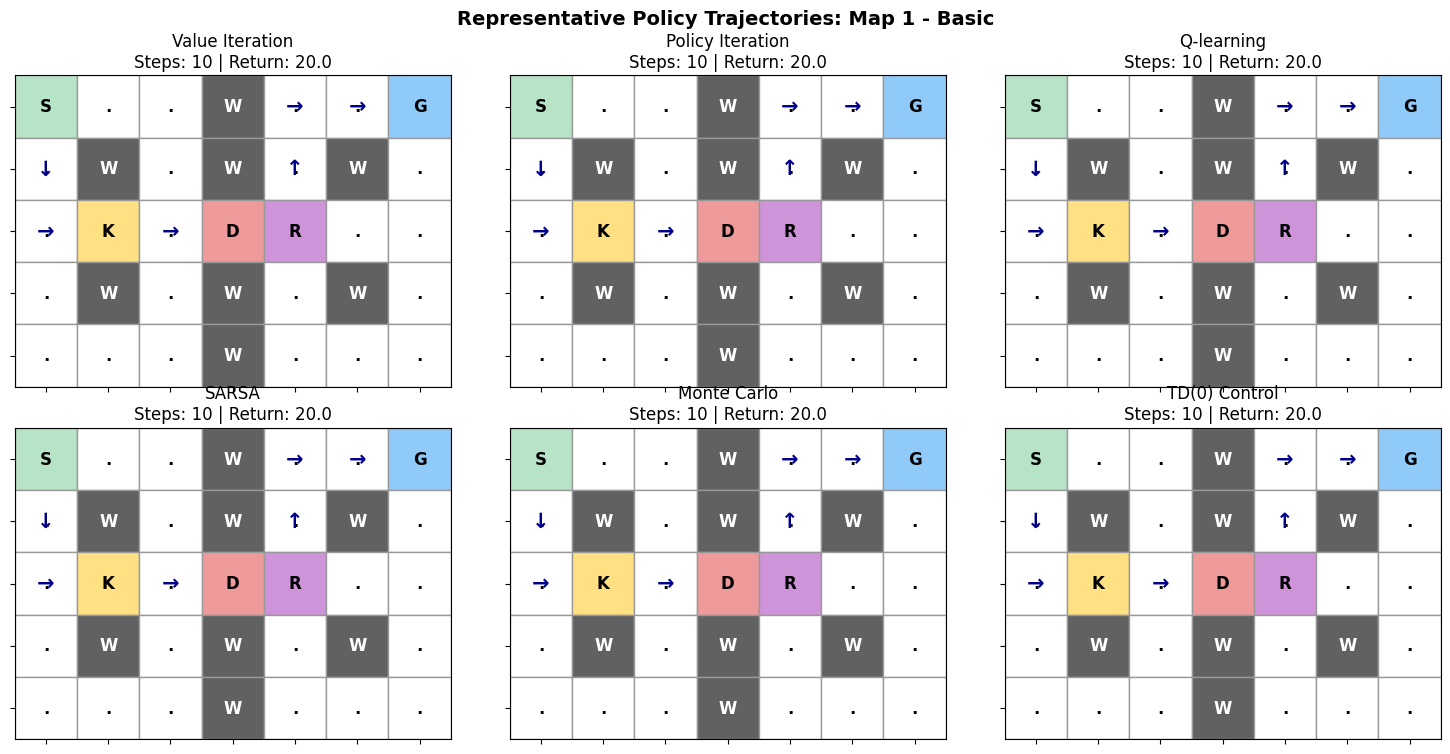

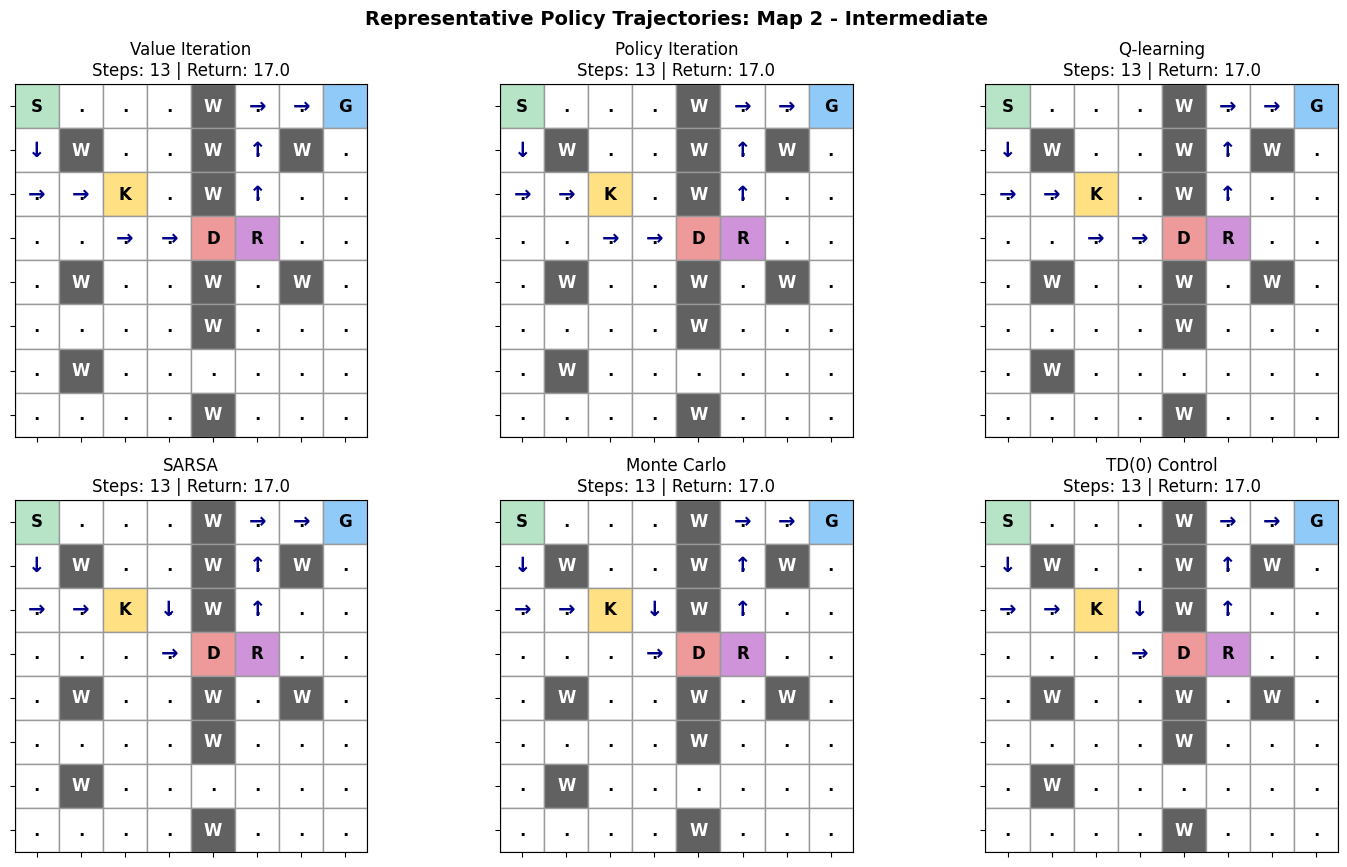

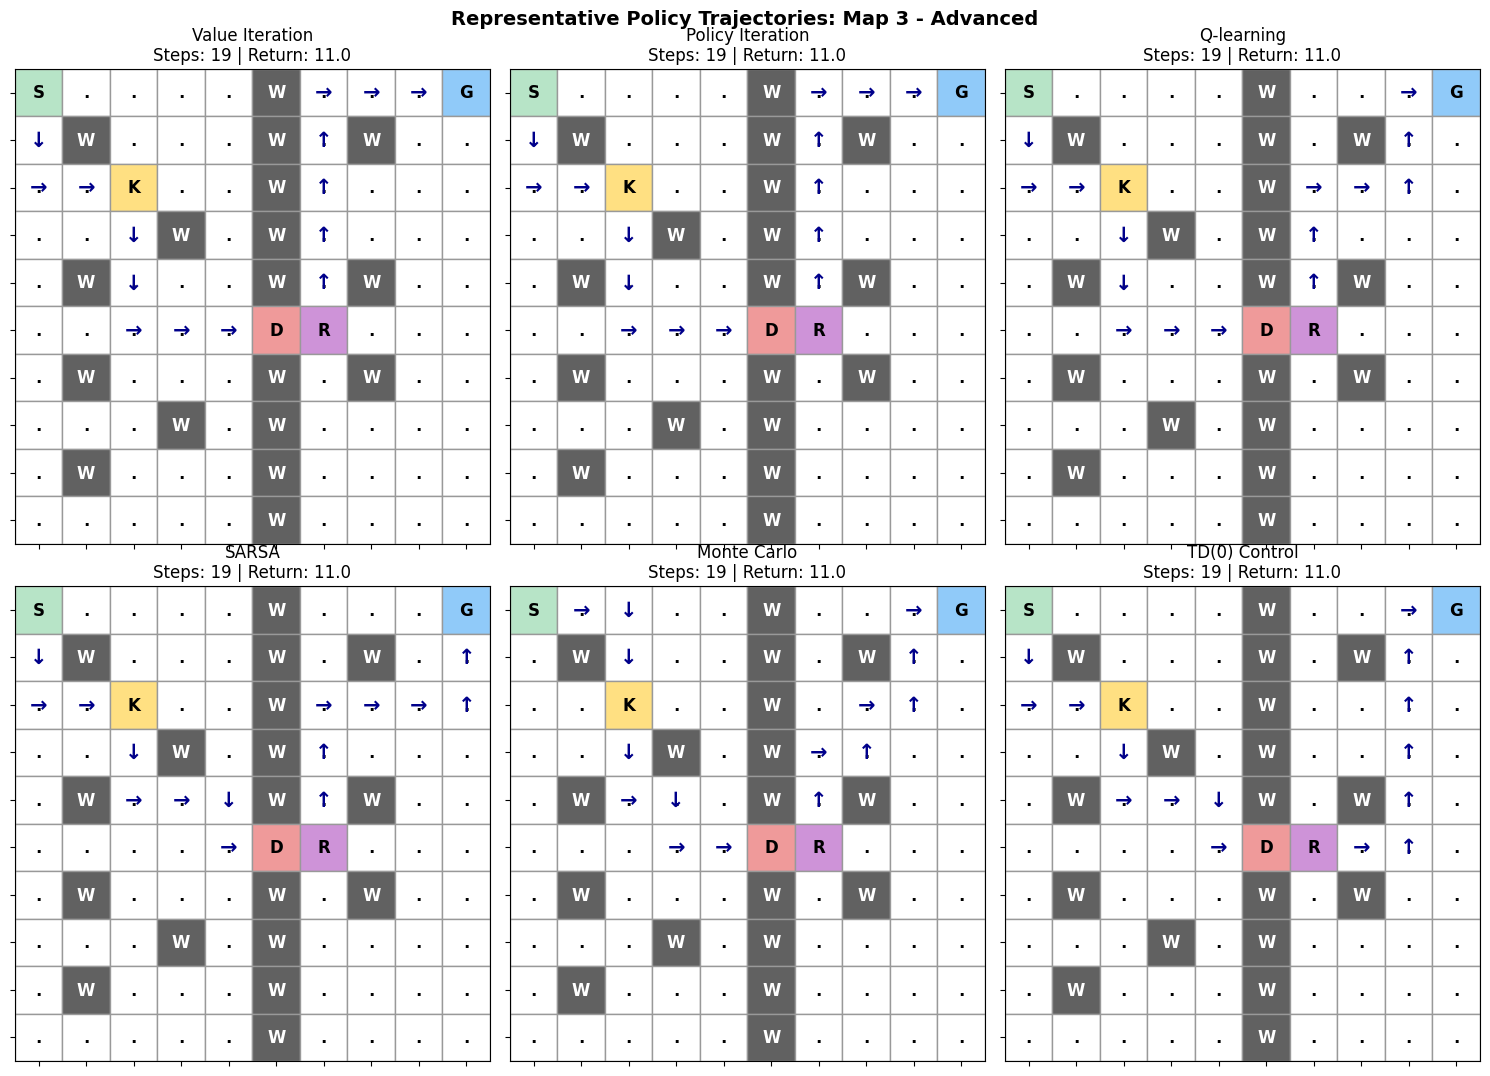

,map,algorithm,reachable_states,success_rate_pct,mean_return,return_std,mean_steps,runtime_seconds,training_episodes,original_key_collected,door_opened,key_recreated,recreation_consumed,goal_reached,all_mechanics_checks_passed
0,Map 1 - Basic,Value Iteration,66,100.0,20.0,0.0,10.0,0.003,0,True,True,True,True,True,True
1,Map 1 - Basic,Policy Iteration,66,100.0,20.0,0.0,10.0,0.027,0,True,True,True,True,True,True
2,Map 1 - Basic,Q-learning,66,100.0,20.0,0.0,10.0,7.475,12000,True,True,True,True,True,True
3,Map 1 - Basic,SARSA,66,100.0,20.0,0.0,10.0,7.189,12000,True,True,True,True,True,True
4,Map 1 - Basic,Monte Carlo,66,100.0,20.0,0.0,10.0,7.688,12000,True,True,True,True,True,True
5,Map 1 - Basic,TD(0) Control,66,100.0,20.0,0.0,10.0,6.899,12000,True,True,True,True,True,True
6,Map 2 - Intermediate,Value Iteration,208,100.0,17.0,0.0,13.0,0.006,0,True,True,True,True,True,True
7,Map 2 - Intermediate,Policy Iteration,208,100.0,17.0,0.0,13.0,0.086,0,True,True,True,True,True,True
8,Map 2 - Intermediate,Q-learning,208,100.0,17.0,0.0,13.0,9.937,12000,True,True,True,True,True,True
9,Map 2 - Intermediate,SARSA,208,100.0,17.0,0.0,13.0,9.153,12000,True,True,True,True,True,True



Total figures generated: 11
Figure directory: /content/Key_Door_Grid_World/figures
01_environment_maps.png
02_learning_curve_map_1__basic.png
02_learning_curve_map_2__intermediate.png
02_learning_curve_map_3__advanced.png
03_success_rate.png
04_mean_return.png
05_mean_steps.png
06_runtime_comparison.png
07_policy_trajectories_map_1__basic.png
07_policy_trajectories_map_2__intermediate.png
07_policy_trajectories_map_3__advanced.png


In [17]:
FIGURES_DIR = Path("Key_Door_Grid_World") / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
algorithm_order = list(ALGORITHMS.keys())
WINDOW = 200
ARROW_FOR_DELTA = {(-1, 0): "↑", (1, 0): "↓", (0, -1): "←", (0, 1): "→"}

def save_figure(fig, filename):
    fig.savefig(FIGURES_DIR / filename, dpi=300, bbox_inches="tight", facecolor="white")
    plt.show()
    plt.close(fig)

def safe_filename(name):
    return name.lower().replace(" ", "_").replace("-", "")

for variable in ["MAPS", "results_df", "learning_curves", "representative_episodes", "ALGORITHMS"]:
    if variable not in globals():
        raise NameError(f"Missing required variable: {variable}")

if results_df.empty:
    raise ValueError("results_df is empty. Run training first.")

fig, axes = plt.subplots(1, len(MAPS), figsize=(5 * len(MAPS), 4))
for ax, (name, grid) in zip(np.atleast_1d(axes), MAPS.items()):
    render_map(grid, ax=ax, title=name)
fig.suptitle("Key-Door Grid World: Environment Maps", fontsize=16, fontweight="bold")
fig.tight_layout()
save_figure(fig, "01_environment_maps.png")

for map_name in MAPS:
    fig, ax = plt.subplots(figsize=(12, 5))
    plotted = False
    for algorithm_name in ["Q-learning", "SARSA", "Monte Carlo", "TD(0) Control"]:
        values = learning_curves.get((map_name, algorithm_name))
        if values is None or len(values) == 0:
            continue
        series = pd.Series(values, dtype=float)
        smooth = series.rolling(window=WINDOW, min_periods=1).mean()
        ax.plot(np.arange(1, len(series) + 1), smooth, label=algorithm_name, linewidth=1.5)
        plotted = True
    ax.set_title(f"Learning Curves - {map_name}", fontsize=14)
    ax.set_xlabel("Training Episode")
    ax.set_ylabel("Moving Average Episode Return")
    ax.grid(True, alpha=0.3)
    if plotted:
        ax.legend()
    else:
        ax.text(0.5, 0.5, "No learning-curve data available", ha="center", va="center", transform=ax.transAxes)
    fig.tight_layout()
    save_figure(fig, f"02_learning_curve_{safe_filename(map_name)}.png")

metric_specs = [
    ("success_rate_pct", "Success Rate (%)", "03_success_rate.png"),
    ("mean_return", "Mean Episode Return", "04_mean_return.png"),
    ("mean_steps", "Mean Steps to Goal", "05_mean_steps.png"),
    ("runtime_seconds", "Training Runtime (seconds)", "06_runtime_comparison.png")
]

for metric, ylabel, filename in metric_specs:
    if metric not in results_df.columns:
        print(f"Skipping missing metric: {metric}")
        continue
    pivot = results_df.pivot_table(index="map", columns="algorithm", values=metric, aggfunc="mean")
    pivot = pivot.reindex(index=list(MAPS.keys()), columns=algorithm_order)
    fig, ax = plt.subplots(figsize=(13, 5.5))
    pivot.plot(kind="bar", ax=ax, width=0.8)
    ax.set_title(f"{ylabel} by Map and Algorithm", fontsize=14, fontweight="bold")
    ax.set_xlabel("Environment Map")
    ax.set_ylabel(ylabel)
    ax.grid(axis="y", alpha=0.3)
    ax.tick_params(axis="x", rotation=12)
    ax.legend(title="Algorithm", bbox_to_anchor=(1.02, 1), loc="upper left")
    fig.tight_layout()
    save_figure(fig, filename)

for map_name, grid in MAPS.items():
    env = KeyDoorEnv(grid)
    available = [name for name in algorithm_order if (map_name, name) in representative_episodes]
    ncols = 3
    nrows = max(1, math.ceil(len(available) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, max(3.8, env.rows * 0.55) * nrows), squeeze=False)
    if not available:
        axes[0, 0].text(0.5, 0.5, "No representative trajectories available", ha="center", va="center")
        axes[0, 0].axis("off")
    for ax, algorithm_name in zip(axes.flat, available):
        episode = representative_episodes[(map_name, algorithm_name)]
        path = episode["path"]
        render_map(grid, ax=ax, title=algorithm_name)
        for current, nxt in zip(path[:-1], path[1:]):
            r, c = current[:2]
            nr, nc = nxt[:2]
            delta = (nr - r, nc - c)
            if delta in ARROW_FOR_DELTA and grid[r][c] == ".":
                ax.text(c, r, ARROW_FOR_DELTA[delta], ha="center", va="center", fontsize=15, color="darkblue", fontweight="bold")
        ax.set_title(f"{algorithm_name}\nSteps: {episode['steps']} | Return: {episode['return']:.1f}")
    for ax in list(axes.flat)[len(available):]:
        ax.axis("off")
    fig.suptitle(f"Representative Policy Trajectories: {map_name}", fontsize=14, fontweight="bold")
    fig.tight_layout()
    save_figure(fig, f"07_policy_trajectories_{safe_filename(map_name)}.png")

display(results_df.round(3))
figure_files = sorted(FIGURES_DIR.glob("*.png"))
print(f"\nTotal figures generated: {len(figure_files)}")
print(f"Figure directory: {FIGURES_DIR.resolve()}")
for file in figure_files:
    print(file.name)

## Analyze stability and reward


In [18]:
MULTI_SEEDS = [11, 22, 33, 44, 55]
ROBUSTNESS_ALGORITHMS = {
    "Q-learning": lambda env, seed: q_learning(env, episodes=1000, seed=seed),
    "SARSA": lambda env, seed: sarsa(env, episodes=1000, seed=seed),
    "Monte Carlo": lambda env, seed: monte_carlo_control(env, episodes=1000, seed=seed),
    "TD(0) Control": lambda env, seed: td_zero_control(env, episodes=1000, seed=seed)
}
robustness_rows = []

for map_name, grid in MAPS.items():
    env = KeyDoorEnv(grid)
    for algorithm_name, train_function in ROBUSTNESS_ALGORITHMS.items():
        for seed in MULTI_SEEDS:
            policy, info = train_function(env, seed)
            metrics = evaluate_policy(env, policy, episodes=1)
            robustness_rows.append({
                "map": map_name,
                "algorithm": algorithm_name,
                "seed": seed,
                "success_rate_pct": metrics["success_rate_pct"],
                "mean_return": metrics["mean_return"],
                "mean_steps": metrics["mean_steps"],
                "training_time_seconds": info["runtime_seconds"]
            })

robustness_df = pd.DataFrame(robustness_rows)
robustness_summary = robustness_df.groupby(["map", "algorithm"]).agg(
    success_mean_pct=("success_rate_pct", "mean"),
    success_std_pct=("success_rate_pct", "std"),
    return_mean=("mean_return", "mean"),
    return_std=("mean_return", "std"),
    steps_mean=("mean_steps", "mean"),
    training_time_mean=("training_time_seconds", "mean")
).reset_index().fillna(0)
display(robustness_summary.round(3))

reward_configs = {
    "Baseline": dict(REWARDS),
    "Higher step penalty": {**REWARDS, "step": -2}
}
reward_rows = []
reward_map = MAPS["Map 1 - Basic"]
for config_name, reward_config in reward_configs.items():
    env = KeyDoorEnv(reward_map, rewards=reward_config)
    policy, info = value_iteration(env)
    metrics = evaluate_policy(env, policy, episodes=1)
    reward_rows.append({
        "configuration": config_name,
        "step_reward": reward_config["step"],
        "success": metrics["goal_reached"],
        "return": metrics["mean_return"],
        "steps": metrics["mean_steps"],
        "iterations": info["iterations"],
        "runtime_seconds": info["runtime_seconds"]
    })
reward_comparison_df = pd.DataFrame(reward_rows)
display(reward_comparison_df.round(3))

,map,algorithm,success_mean_pct,success_std_pct,return_mean,return_std,steps_mean,training_time_mean
0,Map 1 - Basic,Monte Carlo,100.0,0.0,20.0,0.0,10.0,1.067
1,Map 1 - Basic,Q-learning,100.0,0.0,20.0,0.0,10.0,1.267
2,Map 1 - Basic,SARSA,100.0,0.0,20.0,0.0,10.0,1.112
3,Map 1 - Basic,TD(0) Control,100.0,0.0,20.0,0.0,10.0,1.086
4,Map 2 - Intermediate,Monte Carlo,100.0,0.0,17.0,0.0,13.0,1.386
5,Map 2 - Intermediate,Q-learning,100.0,0.0,17.0,0.0,13.0,1.551
6,Map 2 - Intermediate,SARSA,100.0,0.0,17.0,0.0,13.0,1.424
7,Map 2 - Intermediate,TD(0) Control,100.0,0.0,17.0,0.0,13.0,1.316
8,Map 3 - Advanced,Monte Carlo,100.0,0.0,11.0,0.0,19.0,1.631
9,Map 3 - Advanced,Q-learning,100.0,0.0,11.0,0.0,19.0,2.177


,configuration,step_reward,success,return,steps,iterations,runtime_seconds
0,Baseline,-1,True,20.0,10.0,12,0.002
1,Higher step penalty,-2,True,10.0,10.0,12,0.002


## Final export


In [19]:
import json
import shutil
import zipfile
from pathlib import Path

for folder in (RESULTS_DIR, FIGURES_DIR, MAPS_DIR):
    folder.mkdir(parents=True, exist_ok=True)

results_df.to_csv(RESULTS_DIR / "algorithm_comparison.csv", index=False, encoding="utf-8-sig")
results_df.to_json(RESULTS_DIR / "algorithm_comparison.json", orient="records", force_ascii=False, indent=2)
robustness_df.to_csv(RESULTS_DIR / "robustness_by_seed.csv", index=False, encoding="utf-8-sig")
robustness_summary.to_csv(RESULTS_DIR / "robustness_summary.csv", index=False, encoding="utf-8-sig")
reward_comparison_df.to_csv(RESULTS_DIR / "reward_comparison.csv", index=False, encoding="utf-8-sig")

map_config = {
    "project": "Key-Door Grid World",
    "state": ["row", "col", "has_key", "door_open", "recreation_available"],
    "actions": ACTION_NAMES,
    "rewards": REWARDS,
    "symbols": map_legend,
    "maps": MAPS
}
with open(MAPS_DIR / "map_configurations.json", "w", encoding="utf-8") as f:
    json.dump(map_config, f, ensure_ascii=False, indent=2)

experiment_config = {
    "seed": SEED, "gamma": GAMMA, "theta": THETA, "max_steps": MAX_STEPS,
    "evaluation_episodes": EVAL_EPISODES, "q_episodes": Q_EPISODES,
    "sarsa_episodes": SARSA_EPISODES, "mc_episodes": MC_EPISODES,
    "td_episodes": TD_EPISODES, "alpha": ALPHA,
    "epsilon_start": EPSILON_START, "epsilon_end": EPSILON_END,
    "epsilon_decay": EPSILON_DECAY, "robustness_seeds": MULTI_SEEDS,
    "note": "Deterministic environment; policy evaluation is one representative rollout."
}
with open(RESULTS_DIR / "experiment_config.json", "w", encoding="utf-8") as f:
    json.dump(experiment_config, f, ensure_ascii=False, indent=2)

def state_to_key(state):
    return ",".join(map(str, state))

learning_curves_export = {
    f"{map_name}|||{algorithm}": [float(x) for x in values]
    for (map_name, algorithm), values in learning_curves.items()
}
with open(RESULTS_DIR / "learning_curves.json", "w", encoding="utf-8") as f:
    json.dump(learning_curves_export, f, ensure_ascii=False)

policies_export = {}
for (map_name, algorithm), policy in trained_policies.items():
    policies_export[f"{map_name}|||{algorithm}"] = {
        state_to_key(state): int(action) for state, action in policy.items()
    }
with open(RESULTS_DIR / "trained_policies.json", "w", encoding="utf-8") as f:
    json.dump(policies_export, f, ensure_ascii=False)

trajectories_export = {}
for (map_name, algorithm), episode in representative_episodes.items():
    trajectories_export[f"{map_name}|||{algorithm}"] = {
        "return": float(episode["return"]), "steps": int(episode["steps"]),
        "success": bool(episode["success"]),
        "events": episode["events"],
        "path": [list(map(int, state)) for state in episode["path"]]
    }
with open(RESULTS_DIR / "representative_trajectories.json", "w", encoding="utf-8") as f:
    json.dump(trajectories_export, f, ensure_ascii=False, indent=2)

def export_state_mapping(mapping):
    return {state_to_key(state): np.asarray(value).tolist() if isinstance(value, np.ndarray) else float(value)
            for state, value in mapping.items()}

algorithm_diagnostics = {}
for (map_name, algorithm), info in trained_infos.items():
    record = {k: v for k, v in info.items() if k not in ("Q", "values", "learning_returns")}
    if "Q" in info:
        record["Q"] = export_state_mapping(info["Q"])
    if "values" in info:
        record["state_values"] = export_state_mapping(info["values"])
    algorithm_diagnostics[f"{map_name}|||{algorithm}"] = record
with open(RESULTS_DIR / "algorithm_diagnostics.json", "w", encoding="utf-8") as f:
    json.dump(algorithm_diagnostics, f, ensure_ascii=False)

reachable_export = {}
for map_name, grid in MAPS.items():
    env = KeyDoorEnv(grid)
    reachable_export[map_name] = [list(map(int, state)) for state in env.reachable_states()]
with open(MAPS_DIR / "reachable_states.json", "w", encoding="utf-8") as f:
    json.dump(reachable_export, f, ensure_ascii=False)

manifest = {
    "project": "Key-Door Grid World",
    "tables": sorted(x.name for x in RESULTS_DIR.glob("*")),
    "figures": sorted(x.name for x in FIGURES_DIR.glob("*.png")),
    "map_files": sorted(x.name for x in MAPS_DIR.glob("*"))
}
with open(RESULTS_DIR / "artifact_manifest.json", "w", encoding="utf-8") as f:
    json.dump(manifest, f, ensure_ascii=False, indent=2)

try:
    from google.colab import drive
except ImportError as exc:
    raise RuntimeError(
        "Google Drive export requires Google Colab. Open this notebook in Colab, "
        "run Runtime > Run all, then run this final cell."
    ) from exc

drive.mount("/content/drive", force_remount=False)
DRIVE_OUTPUT_DIR = Path("/content/drive/MyDrive/Key_Door_Grid_World")
DRIVE_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
LOCAL_PROJECT_DIR = RESULTS_DIR.parent

for subfolder in ("results", "figures", "maps"):
    source_dir = LOCAL_PROJECT_DIR / subfolder
    destination_dir = DRIVE_OUTPUT_DIR / subfolder
    if source_dir.exists():
        shutil.copytree(source_dir, destination_dir, dirs_exist_ok=True)

zip_path = DRIVE_OUTPUT_DIR / "Key_Door_Grid_World_All_Results.zip"
with zipfile.ZipFile(zip_path, "w", compression=zipfile.ZIP_DEFLATED) as archive:
    for file_path in DRIVE_OUTPUT_DIR.rglob("*"):
        if file_path.is_file() and file_path != zip_path:
            archive.write(file_path, file_path.relative_to(DRIVE_OUTPUT_DIR))

print("\nEXPORT COMPLETED")
print(f"Google Drive folder: {DRIVE_OUTPUT_DIR}")
print(f"ZIP archive: {zip_path}")
print(f"Figures exported: {len(list((DRIVE_OUTPUT_DIR / 'figures').glob('*.png')))}")
print("Exported: result tables, configurations, reachable states, learning curves, policies, trajectories, figures, and manifest.")


Mounted at /content/drive

EXPORT COMPLETED
Google Drive folder: /content/drive/MyDrive/Key_Door_Grid_World
ZIP archive: /content/drive/MyDrive/Key_Door_Grid_World/Key_Door_Grid_World_All_Results.zip
Figures exported: 11
Exported: result tables, configurations, reachable states, learning curves, policies, trajectories, figures, and manifest.


##
LINK GOOGLE DRIVE:    
https://drive.google.com/drive/folders/16A7-D4z_TXG31AHYCB6GJCaurfrWq9pr?usp=sharing